# 01 – Khám phá dữ liệu CIC-IDS2017

Đọc 8 file CSV của CIC-IDS2017, đo mức mất cân bằng giữa các lớp và thống kê lỗi dữ liệu. Notebook chỉ đọc và đếm; làm sạch ở notebook 02.

**Đầu vào:** `data/MachineLearningCVE/*.csv` (8 file, 844 MB).
**Đầu ra:** không ghi file.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)  # dữ liệu có 80 cột, mặc định pandas chỉ hiện khoảng 20
sns.set_theme(style="whitegrid")

## 1. Tìm file dữ liệu

Mỗi file ứng với một ngày hoặc nửa ngày thu dữ liệu, từ thứ Hai đến thứ Sáu. `rglob` tìm trong mọi thư mục con của `data/`, nên không phụ thuộc cách giải nén.

In [2]:
DATA_DIR = Path("../data")

csv_files = sorted(DATA_DIR.rglob("*.csv"))  # để mỗi lần chạy có cùng 1 thứ tự
if not csv_files:
    raise FileNotFoundError(f"No CSV files found in {DATA_DIR.resolve()}")

for f in csv_files:
    print(f.name)
print(f"\nTotal: {len(csv_files)} files")

Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Friday-WorkingHours-Morning.pcap_ISCX.csv
Monday-WorkingHours.pcap_ISCX.csv
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Tuesday-WorkingHours.pcap_ISCX.csv
Wednesday-workingHours.pcap_ISCX.csv

Total: 8 files


## 2. Đọc và gộp

Ba xử lý khi đọc, dùng lại y hệt ở notebook 02:
- `encoding="latin-1"`: nhãn Web Attack chứa byte không hợp lệ trong UTF-8; sau khi gộp, ký tự lỗi được thay bằng `-`.
- `str.strip()` tên cột: tên cột gốc có dấu cách ở đầu (`" Label"`).
- `float64` → `float32`: giảm gần một nửa bộ nhớ, cả bảng (2,8 triệu dòng × 79 cột) còn khoảng 1,9 GB.

In [3]:
frames = []
for f in csv_files:
    part = pd.read_csv(f, encoding="latin-1", low_memory=False)
    part.columns = part.columns.str.strip()
    float_cols = part.select_dtypes("float64").columns
    part[float_cols] = part[float_cols].astype("float32")
    part["source_file"] = f.name  # để truy ngược một dòng lạ về file gốc
    frames.append(part)
    print(f"Read {f.name}: {len(part):,} rows")

df = pd.concat(frames, ignore_index=True)  # đánh lại số thứ tự dòng từ 0, tránh lặp giữa các file
del frames  

# Nhãn Web Attack chứa ký tự gạch ngang lỗi mã hóa: thay mọi ký tự ngoài ASCII bằng "-"
df["Label"] = df["Label"].str.replace(r"[^\x00-\x7F]+", "-", regex=True).str.strip()

print(f"\nShape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Memory usage: {df.memory_usage(deep=True).sum() / 1e9:.2f} GB")

Read Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv: 225,745 rows
Read Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv: 286,467 rows
Read Friday-WorkingHours-Morning.pcap_ISCX.csv: 191,033 rows
Read Monday-WorkingHours.pcap_ISCX.csv: 529,918 rows
Read Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv: 288,602 rows
Read Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv: 170,366 rows
Read Tuesday-WorkingHours.pcap_ISCX.csv: 445,909 rows
Read Wednesday-workingHours.pcap_ISCX.csv: 692,703 rows

Shape: 2,830,743 rows × 80 columns
Memory usage: 1.91 GB


In [4]:
df.head()

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,source_file
0,54865,3,2,0,12,0,6,6,6.0,0.0,0,0,0.0,0.0,4.000000e+06,666666.687500,3.0,0.0,3,3,3,3.0,0.0,3,3,0,0.0,0.0,0,0,0,0,0,0,40,0,666666.687500,0.000000,6,6,6.0,0.0,0.0,0,0,0,0,1,0,0,0,0,9.0,6.0,0.0,40,0,0,0,0,0,0,2,12,0,0,33,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
1,55054,109,1,1,6,6,6,6,6.0,0.0,6,6,6.0,0.0,1.100917e+05,18348.623047,109.0,0.0,109,109,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0,0,0,20,20,9174.311523,9174.311523,6,6,6.0,0.0,0.0,0,0,0,0,1,1,0,0,1,9.0,6.0,6.0,20,0,0,0,0,0,0,1,6,1,6,29,256,0,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
2,55055,52,1,1,6,6,6,6,6.0,0.0,6,6,6.0,0.0,2.307692e+05,38461.539062,52.0,0.0,52,52,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0,0,0,20,20,19230.769531,19230.769531,6,6,6.0,0.0,0.0,0,0,0,0,1,1,0,0,1,9.0,6.0,6.0,20,0,0,0,0,0,0,1,6,1,6,29,256,0,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
3,46236,34,1,1,6,6,6,6,6.0,0.0,6,6,6.0,0.0,3.529412e+05,58823.531250,34.0,0.0,34,34,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0,0,0,20,20,29411.765625,29411.765625,6,6,6.0,0.0,0.0,0,0,0,0,1,1,0,0,1,9.0,6.0,6.0,20,0,0,0,0,0,0,1,6,1,6,31,329,0,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
4,54863,3,2,0,12,0,6,6,6.0,0.0,0,0,0.0,0.0,4.000000e+06,666666.687500,3.0,0.0,3,3,3,3.0,0.0,3,3,0,0.0,0.0,0,0,0,0,0,0,40,0,666666.687500,0.000000,6,6,6.0,0.0,0.0,0,0,0,0,1,0,0,0,0,9.0,6.0,0.0,40,0,0,0,0,0,0,2,12,0,0,32,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv


## 3. Phân phối lớp

15 nhãn gốc: BENIGN và 14 kiểu tấn công, đếm trước khi gộp nhãn và xóa trùng. Biểu đồ dùng thang log vì BENIGN nhiều gấp khoảng 200.000 lần Heartbleed.

In [5]:
counts = df["Label"].value_counts()
label_table = pd.DataFrame({
    "Count": counts,
    "Share (%)": (counts / counts.sum() * 100).round(4),
})
label_table

,Count,Share (%)
Label,,
BENIGN,2273097,80.3004
DoS Hulk,231073,8.1630
PortScan,158930,5.6144
DDoS,128027,4.5227
DoS GoldenEye,10293,0.3636
FTP-Patator,7938,0.2804
SSH-Patator,5897,0.2083
DoS slowloris,5796,0.2048
DoS Slowhttptest,5499,0.1943


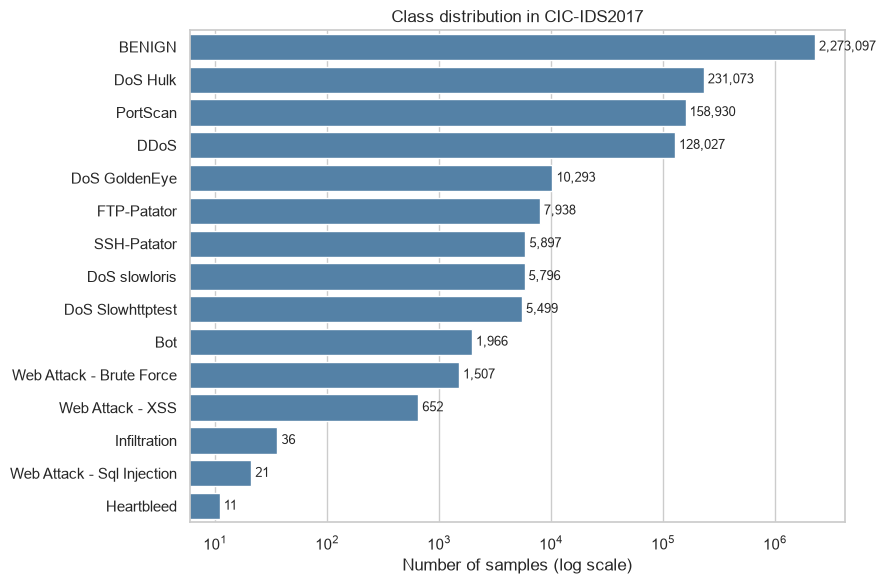

In [6]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(x=counts.values, y=counts.index, ax=ax, color="steelblue")
ax.set_xscale("log")  # BENIGN nhiều gấp khoảng 200.000 lần Heartbleed, trục thường không thấy lớp hiếm
ax.set_xlabel("Number of samples (log scale)")
ax.set_ylabel("")
ax.set_title("Class distribution in CIC-IDS2017")
for i, v in enumerate(counts.values):
    ax.text(v, i, f" {v:,}", va="center", fontsize=9)
plt.tight_layout()
plt.show()

## 4. Chất lượng dữ liệu

Chỉ đếm, chưa sửa:

| Lỗi | Ảnh hưởng |
|---|---|
| NaN, Infinity | Sinh ra ở `Flow Bytes/s`, `Flow Packets/s` khi flow có thời lượng 0 (chia cho 0). Phần lớn mô hình không nhận các giá trị này |
| Dòng trùng | Cùng một flow có thể rơi vào cả train lẫn test, làm điểm test cao giả tạo |
| Cột hằng số | Không mang thông tin phân biệt lớp |

In [7]:
feature_cols = df.columns.drop(["Label", "source_file"])
numeric = df[feature_cols].select_dtypes("number")

nan_per_col = numeric.isna().sum()
inf_per_col = np.isinf(numeric).sum()  # isna() không coi Infinity là ô trống nên phải đếm riêng
quality = pd.DataFrame({"NaN count": nan_per_col, "Infinity count": inf_per_col})
# chỉ giữ các cột có ít nhất một lỗi
quality = quality[(quality["NaN count"] > 0) | (quality["Infinity count"] > 0)]

print("Columns with NaN or Infinity:")
quality

Columns with NaN or Infinity:


,NaN count,Infinity count
Flow Bytes/s,1358,1509
Flow Packets/s,0,2867


In [8]:
n_dup = df.duplicated(subset=list(feature_cols) + ["Label"]).sum()
print(f"Exact duplicate rows: {n_dup:,} ({n_dup / len(df) * 100:.2f}%)")

# cột hằng số: chỉ có 1 giá trị (dropna=False để NaN cũng được tính là một giá trị)
constant_cols = [c for c in feature_cols if df[c].nunique(dropna=False) <= 1]
print(f"\nConstant columns: {len(constant_cols)}")
print(constant_cols)

Exact duplicate rows: 330,995 (11.69%)

Constant columns: 8
['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
